# Clasificación de spam con redes recurrentes y BERT

Proyecto de Inteligencia Artificial de U-tad. Compara LSTM, BiLSTM, BiLSTM con embeddings GloVe y BERT en el mismo problema de clasificación.
Las salidas guardadas son métricas y gráficas agregadas. Consulta la [guía de ejecución](../README.md#run-the-notebooks) para preparar los CSV.

In [ ]:
from pathlib import Path

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Añade aquí los import que utilices en tu código
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from sklearn.metrics import accuracy_score, classification_report, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay, recall_score, precision_score, log_loss


from tensorflow.keras.layers import Embedding, LSTM, Bidirectional, Dense, Dropout
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from sklearn.model_selection import train_test_split
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

# Para calcular los pesos de cada clase 
from sklearn.utils import class_weight

# Para hacer el train test split he usado sckit-learn
from sklearn.model_selection import train_test_split

# Para BERT
import keras_nlp

# Para parte de la limpieza del datset
import contractions #!pip install contractions
import html
import re

pd.set_option('display.max_rows', 36)
pd.set_option("display.max_colwidth", 150)
plt.rcParams['figure.figsize'] = (12, 6)
np.random.seed(33)
tf.random.set_seed(33)

seed = 33

## Carga de Datos

Se cargan los conjuntos **train** y **test** desde la carpeta `spam_data`, asumiendo esta estructura:

```text
Spam_Data/
├─ train.csv
├─ test.csv
├─ sample_submission.csv
```

Contenido:

- `train.csv` contiene las columnas **`row_id`**, **`text`** y **`spam_label`** (0 = NO SPAM, 1 = SPAM).
- `test.csv` contiene las columnas **`row_id`** y **`text`** (sin etiquetas).
- `sample_submission.csv` muestra el formato de entrega requerido.

Las etiquetas se almacenan como enteros:

- `0` → NO SPAM
- `1` → SPAM

In [ ]:
DATASET_DIR = Path(os.environ.get("SPAM_DATA_DIR", PROJECT_ROOT / "data" / "Spam_Data"))

# Cargar los archivos de test
test = pd.read_csv(f"{DATASET_DIR}/test.csv", index_col="row_id")

# Cargar los archivos de train
train = pd.read_csv(f"{DATASET_DIR}/train.csv", index_col="row_id")
print(f"Filas de entrenamiento: {len(train):,}; filas de predicción: {len(test):,}")

## Desarrollo de la Práctica

### 1. Analisis y Limpieza del dataset
- Antes de empezar a realizar cualquier tipo de acción sobre los datos, conviene revisarlos y limpiarlos. Por ejemplo, en el viendo la salida de algunas de las conlumnas de dataset podemos ver caracteres especiales (`\n`, `-` o `Ü` )
- Tras analizar el dataset he decidido ademas usar `contractions` para eliminar las contracciones del inglés (por ejemplo can't a can not) para no perder significados
- Para hacer las expresiones regulares me he basado en ejemplos de internet y la página https://regex101.com/ para hacer, probar y comparar

In [ ]:
#!pip install contractions

## Creditos a este hilo por la idea de cambiar contracciones para el modelo (p. ej: can't -> can not)
## https://stackoverflow.com/questions/15547409/how-to-get-rid-of-punctuation-using-nltk-tokenizer#comment98704112_41024113

def limpiar_texto_individual(texto: str) -> str:

    # Decodificar HTML (ej: &amp; -> &)
    texto = html.unescape(texto)
        
    # Cambiar simbolos por token [MONEY]
    texto = re.sub(r'[$£]|(usd|eur)', ' [MONEY] ', texto, flags=re.IGNORECASE)
    
    # Cambiar enlace por un token 
    texto = re.sub(r'https?://\S+|www\.\S+', ' [URL] ', texto)

    # Cambiar correos por un token
    texto = re.sub(r'\S+@\S+', ' [EMAIL] ', texto)

    # Convertir a minúsculas
    texto = texto.lower()

    # Normalizar espacios y saltos de línea
    texto = texto.replace("\r\n", "\n").replace("\r", "\n")

    # Padding de Puntuación para que sean tokens independientes 
    texto = re.sub(r"([!?.,:;%*\"'()])", r" \1 ", texto)
    
    # Quitar contracciones ej: can't -> can not
    texto = contractions.fix(texto)

    # Eliminar signos y caracteres especiales
    #texto = re.sub(r"[^a-z0-9\sáéíóúñü']", "", texto)
    #4. V2
    #texto = re.sub(r"[^a-z0-9\s!?\$%&@#.,:;'\"\-_/]", " ", texto)
    #4. V3
    texto = re.sub(r"[^a-zA-Z0-9\sáéíóúñü!?.,:;%*\"'()\[\]\-_]", " ", texto)
    
    # Quitar espacios múltiples
    texto = re.sub(r"\s+", " ", texto).strip()
    
    return texto


def limpiar_dataframe(dataset, col_a_limpiar="text"):
    dataset[col_a_limpiar] = dataset[col_a_limpiar].apply(limpiar_texto_individual)
    return dataset

train = limpiar_dataframe(train)
test = limpiar_dataframe(test)

In [ ]:
print(train["spam_label"].value_counts().rename(index={0: "No spam", 1: "Spam"}))

In [ ]:
from collections import Counter

df = train.copy() 
df = limpiar_dataframe(df)

# Percentil 95 de la longitud de los textos
df["len"] = df["text"].str.split().str.len()
print("Percentil 95 de la longitud de los textos", int(np.percentile(df["len"], 95)))

# Contar frecuencia de palabras
tokens = " ".join(df["text"]).split()
word_counts = Counter(tokens)

# Tamaño total del vocabulario
print("Tamaño del vocabulario:", len(word_counts))

# Calcular el vocabulario mínimo que cubre el 95% de los tokens
sorted_counts = word_counts.most_common()
cumulative = np.cumsum([c for _, c in sorted_counts]) / len(tokens)

print("Vocabulario que cubre el 95% ",int((np.argmax(cumulative >= 0.95) + 1)))


- Basado en los resultados de la longitud de los textos y el vocabulario he optado por usar
    - aproximadamente la mitad del percentil 95 (300 palabras) (para las LSTM serian secuencias muy largas si no) ,
    - y redondear el vocabulario a unas 12000 palabras
    - He optado finalmente por usar 100 dimensiones para los embeddings entrenados de 0

In [ ]:
MAX_LEN = 300
MAX_VOCAB = 15000
EMBEDDING_DIM = 100

#### 1.1. Distribucion de spam_label
- Como se puede observar, nos encontramos ante un dataset relativamente desbalanceado, por los que para el entrenamiento (.fit) deberiamos aplicar class_weight para penalizar más los errores de fallar Spam, lo que ademas deberia mejorar el MCC que si no lo aplicamos.

- Ademas, dado es desbalanceo, he optado por usar Recall y Precision, además del accuracy como métrica, pues así, los scores durante la validación deberían penalizar más el clasificar mal el spam, de los cuales tenemos menos.

In [ ]:
print("Distribución de los valores del df (frecuencia):", train['spam_label'].value_counts())

print("En formato de frecuencia relativa: ", train['spam_label'].value_counts(normalize=True) * 100 ) 

In [ ]:
metrics = [
    "accuracy",
    tf.keras.metrics.Recall(name="recall"),       # Spam bien clasificado
    tf.keras.metrics.Precision(name="precision")  # Se equivoca diciendo que es spam
]

### 2. Tokenizar los datos, train test split y calcular los pesos de clase

In [ ]:
filters_to_remove = '"()*+,-/:;<=>\\^`{|}~\t\n'

tokenizer = Tokenizer(
    num_words=MAX_VOCAB, 
    oov_token="<OOV>", 
    filters=filters_to_remove)

tokenizer.fit_on_texts(train["text"])

# Convertir texto a secuencias
X = tokenizer.texts_to_sequences(train["text"])
X_padded = pad_sequences(
                    X, 
                    maxlen=MAX_LEN, 
                    padding='post', 
                    truncating='post')

y = np.array(df["spam_label"])

print("Tamaño del vocabulario:", len(tokenizer.word_index))
print("Forma de X_padded:", X_padded.shape)

In [ ]:
# 70% train, 30% temp
X_train, X_temp, y_train, y_temp = train_test_split(
    X_padded,
    y,
    test_size=0.3,
    random_state=seed,
    stratify=y,
)

# De ese 30%, mitad val y mitad test -> 15/15
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=seed,
    stratify=y_temp,
)

In [ ]:
weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train), # Clases [0, 1]
    y=y_train                   # etiquetas de entrenamiento
)

# Convertimos a diccionario para Keras 
class_weights_dict = dict(enumerate(weights))

print(f"Pesos calculados: {class_weights_dict}")

### 3.1 LSTM solo con Tokenizer
- Primero he decicido probar con un sencillo LSTM y pasar progresivamente a tecnicas mas avanzadas y comparar resultados
- La capa Embedding empieza con valores aleatorios

In [ ]:
model_uni = Sequential([
    Embedding(input_dim=MAX_VOCAB, output_dim=EMBEDDING_DIM),
    LSTM(32),
    Dropout(0.3),
    Dense(1, activation="sigmoid")
])

# Compilamos pasando la lista de métricas
model_uni.compile(optimizer="adam", loss="binary_crossentropy", metrics=metrics)
model_uni.summary()

In [ ]:
# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=5, min_lr=1e-6
)
checkpoint = ModelCheckpoint(
    "best_model_uni.keras", monitor="val_loss", save_best_only=True
)

# Entrenamiento del LSTM
history_uni = model_uni.fit(
    X_train, y_train,
    epochs=30,                
    batch_size=128,           
    validation_data=(X_val, y_val),
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

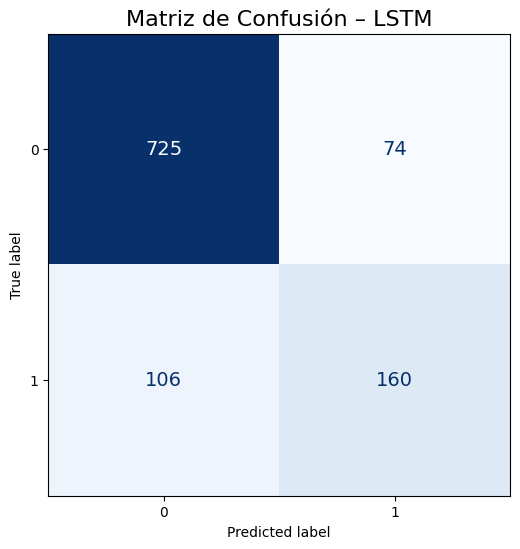

In [77]:
# 1. Predicciones
y_pred_uni = (model_uni.predict(X_test, verbose=0) > 0.8).astype(int).flatten()

# 2. Métricas
print("Accuracy LSTM:", accuracy_score(y_test, y_pred_uni))
print("Matthews Correlation Coefficient (MCC):", matthews_corrcoef(y_test, y_pred_uni))

print("\nReporte de clasificación (LSTM):\n")
print(classification_report(y_test, y_pred_uni, zero_division=0))

# 3. Matriz de confusión
cm_uni = confusion_matrix(y_test, y_pred_uni)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_uni)
disp.plot(cmap="Blues", ax=ax, colorbar=False)

# Ajustes visuales
for text in disp.text_.ravel():
    text.set_fontsize(14)

ax.set_title("Matriz de Confusión – LSTM", fontsize=16)
plt.show()


### 3.1 Bidirectional LSTM solo con Tokenizer
- El LSTM se aplica en los dos sentidos mejorando la capacidad de retener
- La capa Embedding empieza con valores aleatorios

In [ ]:
model_bi = Sequential([
    Embedding(input_dim=MAX_VOCAB, output_dim=EMBEDDING_DIM),
    Bidirectional(LSTM(128)),
    Dense(MAX_LEN, activation="relu"),
    Dropout(0.5),
    Dense(MAX_LEN, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model_bi.compile(optimizer="adam", loss="binary_crossentropy", metrics=metrics)
model_bi.summary()

In [ ]:
# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=2, min_lr=1e-6
)
checkpoint = ModelCheckpoint(
    "best_model_bi.keras", monitor="val_recall", save_best_only=True
)

# Entrenamiento del LSTM
history_bi = model_bi.fit(
    X_train, y_train,
    epochs=30,               
    batch_size=128,           
    validation_data=(X_val, y_val),
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

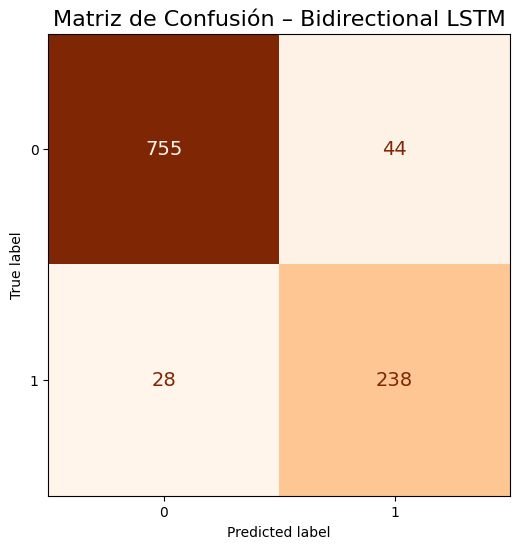

In [84]:
from sklearn.metrics import accuracy_score, classification_report, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predicciones
y_pred_bi = (model_bi.predict(X_test, verbose=0) > 0.8).astype(int).flatten()

# 2. Métricas
print("Accuracy Bidirectional LSTM:", accuracy_score(y_test, y_pred_bi))
print("Matthews Correlation Coefficient (MCC):", matthews_corrcoef(y_test, y_pred_bi))

print("\nReporte de clasificación (Bidirectional LSTM):\n")
print(classification_report(y_test, y_pred_bi, zero_division=0))

# 3. Matriz de confusión
cm_bi = confusion_matrix(y_test, y_pred_bi)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bi)
disp.plot(cmap="Oranges", ax=ax, colorbar=False)

# Ajustes visuales
for text in disp.text_.ravel():
    text.set_fontsize(14)

ax.set_title("Matriz de Confusión – Bidirectional LSTM", fontsize=16)
plt.show()


### 3.2 Bidirectional LSTM con Word2vec 
- La capa Embedding se inicializa con vectores semánticos ya entrenados en millones de frases.
- Inicialmente iba a usar un modelo en formato FastText pero tuve problemas de dependecias en `gensim.models` con un método que estaba deprecado 

In [ ]:
from gensim.downloader import load

# Embeddings GloVe preentrenados con texto de Twitter 
w2v_model = load("glove-twitter-100")

# Confirmamos numero de dimensiones
embed_dim = w2v_model.vector_size
print("Embedding dimension:", embed_dim)


In [ ]:
import numpy as np

# 1. Definir dimensiones 
embedding_dim = w2v_model.vector_size 
print(f"Dimensión de los vectores: {embedding_dim}")

# 2. Inicializar la matriz de embeddings con ceros
# Tamaño: (Vocabulario + 1 para padding, Dimensión del vector)
embedding_matrix = np.zeros((MAX_VOCAB, embedding_dim))

# 3. Llenar la matriz con los pesos pre-entrenados
hits = 0
misses = 0
# Guardamos palabras OOV para analizarlas luego si quieres
oov_words = []

for word, i in tokenizer.word_index.items():
    if i >= MAX_VOCAB:
        continue

    if word in w2v_model:
        embedding_matrix[i] = w2v_model[word]
        hits += 1
    else:
        misses += 1
        oov_words.append(word)

print(f"Palabras encontradas (Hits): {hits}")
print(f"Palabras no encontradas (Misses): {misses}")
print(f"Porcentaje de cobertura: {hits / (hits + misses) * 100:.2f}%")



In [ ]:
model_bi_word2vec = Sequential([
    Embedding(
        input_dim=MAX_VOCAB, 
        output_dim=embed_dim,
        weights=[embedding_matrix],
        trainable=False  # Congelar Word2Vec
    ),
    Bidirectional(LSTM(64,return_sequences=True)),
    Bidirectional(LSTM(34)),
    Dense(MAX_LEN, activation="relu"),
    Dropout(0.5),
    Dense(MAX_LEN, activation="relu"),
    Dropout(0.5),
    Dense(1, activation="sigmoid")
])

model_bi_word2vec.compile(optimizer="adam", loss="binary_crossentropy", metrics=metrics)
model_bi_word2vec.summary()

In [ ]:
# Callbacks
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.5, patience=3, min_lr=1e-6
)
checkpoint = ModelCheckpoint(
    "best_model_bi_word2vec.keras", monitor="val_loss", save_best_only=True
)

# Entrenamiento del LSTM
history_bi_word2vec = model_bi_word2vec.fit(
    X_train, y_train,
    epochs=30,                
    batch_size=128,          
    validation_data=(X_val, y_val),
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr, checkpoint],
    verbose=1
)

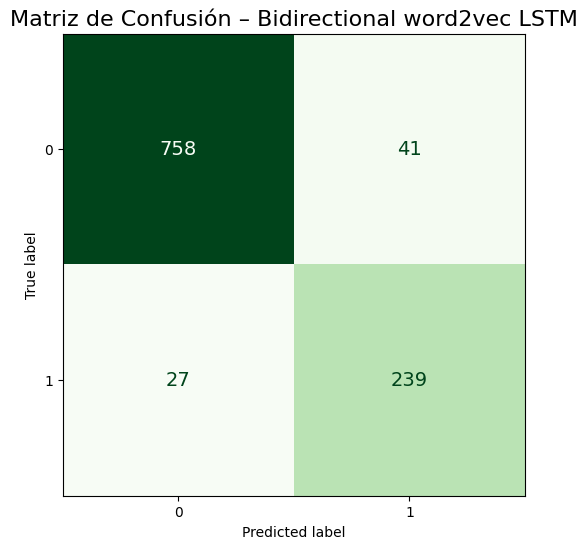

In [95]:
from sklearn.metrics import accuracy_score, classification_report, matthews_corrcoef, confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Predicciones
y_pred_bi = (model_bi_word2vec.predict(X_test, verbose=0) > 0.8).astype(int).flatten()

# 2. Métricas
print("Accuracy Bidirectional word2vec LSTM:", accuracy_score(y_test, y_pred_bi))
print("Matthews Correlation Coefficient (MCC):", matthews_corrcoef(y_test, y_pred_bi))

print("\nReporte de clasificación (Bidirectional word2vec LSTM):\n")
print(classification_report(y_test, y_pred_bi, zero_division=0))

# 3. Matriz de confusión
cm_bi = confusion_matrix(y_test, y_pred_bi)

fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_bi)
disp.plot(cmap="Greens", ax=ax, colorbar=False)

# Ajustes visuales
for text in disp.text_.ravel():
    text.set_fontsize(14)

ax.set_title("Matriz de Confusión – Bidirectional word2vec LSTM", fontsize=16)
plt.show()


### 3.4 Clasificacion con Transfromers y Bert
- Inicialmente había pensado usar la biblioteca de Transformers y Datasets de Hugging face, pero dadas incompatibilidades con las nuevas versiones de Keras y TensorFlow. Y la complejidad de usar PyTorch en el mismo entorno, he optado por usar [KerasHub](https://keras.io/keras_hub/), una libreria de Keras compatible con las nuevas versiones de TensorFlow y que además contiene modelos ya preentrenados y faciles de configurar (usando la Functional API en vez de la Sequential API que hemos visto en clase). Dado que además ya contiene un modelo de la arquitectura BERT casi listo para usar ([BertTextClassifier model](https://keras.io/keras_hub/api/models/bert/bert_text_classifier/#berttextclassifier-class)) he optado por usar este stack para probar a hacer un modelo de clasificación de texto.

- Además así podemos aprovechar la API estándar de Keras (`.compile`, `.fit`, callbacks, metricas, etc.) para el entrenamiento.

- Para simplicidad he usado el metodo `from_preset` que ya incluye el preprocesador [BertTextClassifierPreprocessor](https://keras.io/keras_hub/api/models/bert/bert_text_classifier_preprocessor/#berttextclassifierpreprocessor-class) que genera los token_ids, padding_mask, y segment_ids; y a su vez incluye el tokenizador [BertTokenizer](https://keras.io/keras_hub/api/models/bert/bert_tokenizer), que los pasa directamente al modelo BERT. Además nos permite definir la función de activación de salida e incluso el Dropout.

- Para este ejemplo me he basado en la propia documentación de Keras [https://keras.io/keras_hub/api/models/bert/bert_text_classifier/#berttextclassifier-class]

In [ ]:
## Dado que el train-val-test split inicial se hizo sobre los datos tokenizados, lo volvemos a hacer aquí sobre el texto
X = train["text"]
y = train["spam_label"]   # 0 = No spam, 1 = spam

# 70% train, 30% temp
X_train_bert, X_temp, y_train_bert, y_temp = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=seed,
    stratify=y,
)

# De ese 30%, mitad val y mitad test -> 15/15
X_val_bert, X_test_bert, y_val_bert, y_test_bert = train_test_split(
    X_temp,
    y_temp,
    test_size=0.5,
    random_state=seed,
    stratify=y_temp,
)

In [ ]:
model_name = 'bert_medium_en_uncased' # Otros modelos en https://keras.io/keras_hub/api/models/bert/bert_text_classifier/#berttextclassifier-class

classifier = keras_nlp.models.BertTextClassifier.from_preset(
    model_name,
    num_classes=1,          # salida binaria
    activation="sigmoid",   # prob de spam
    dropout=0.1   
)

classifier.compile(
    loss=keras.losses.BinaryCrossentropy(),
    optimizer=keras.optimizers.Adam(5e-5),
    metrics=metrics,
    jit_compile=True,
)

classifier.summary()

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)
reduce_lr = ReduceLROnPlateau(
    monitor="val_loss", factor=0.9, patience=2, min_lr=1e-6
)
checkpoint = ModelCheckpoint(
    "best_model_bert.keras", monitor="val_loss", save_best_only=False
)

history_bert = classifier.fit(
    x=X_train_bert,
    y=y_train_bert,
    validation_data=(X_val_bert, y_val_bert),
    class_weight=class_weights_dict,
    callbacks=[early_stop, reduce_lr, checkpoint],
    batch_size=32,
    epochs=7,
)

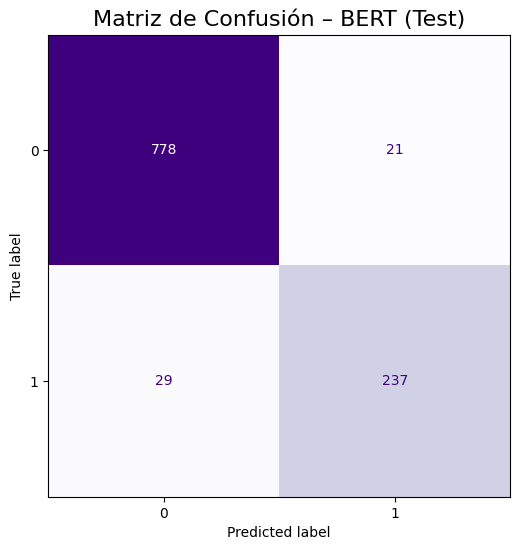

In [119]:
# Predicciones de prob
y_probs = classifier.predict(X_test_bert, batch_size=32).ravel()
y_pred = (y_probs > 0.8).astype(int)

print(f"MCC BERT (test): {matthews_corrcoef(y_test, y_pred):.4f}\n")
print("Reporte de clasificación (test):\n")
print(classification_report(y_test, y_pred, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Purples", ax=ax, colorbar=False)
ax.set_title("Matriz de Confusión – BERT (Test)", fontsize=16)
plt.show()

### 4. Conclusiones: evaluacion, graficos y matrices de confusion 

- Evaluacion de los cuatro modelos creados segun `Loss`, `Accuracy`, `Recall` y `MCC`

In [121]:
# Para LSTMs (uni, bi, w2v): los datos estan tokenizados (usamos X_test e y_test)
# Para BERT usamos el texto crudo que KerasHub maneja el preprocesado (usamos X_test_bert e y_test_bert)

print("--- Evaluación en Conjunto de Test ---\n")

import numpy as np
from sklearn.metrics import accuracy_score, recall_score, precision_score, matthews_corrcoef, log_loss

def evaluar_modelo(modelo, X, y, nombre_modelo):
    """
    Genera predicciones y calcula 5 métricas usando sklearn.
    """
    # Obtener probabilidades (0.0 a 1.0)
    y_probs = modelo.predict(X, verbose=0).ravel()
    
    # Convertir a clases (0 o 1) 
    y_pred = (y_probs > 0.8).astype(int)
    
    # Calcular métricas
    loss = log_loss(y, y_probs, )
    acc = accuracy_score(y, y_pred)
    rec = recall_score(y, y_pred, zero_division=0)
    prec = precision_score(y, y_pred, zero_division=0)
    mcc = matthews_corrcoef(y, y_pred)
    
    return loss, acc, rec, prec, mcc

# EJECUCIÓN

print("--- Evaluación Comparativa Final (Test Set) ---\n")
print(f"{'Modelo':<20} | {'Loss':<8} | {'Acc':<8} | {'Recall':<8} | {'Prec':<8} | {'MCC':<8}")
print("-" * 75)

# 1. LSTM Unidireccional
m1 = evaluar_modelo(model_uni, X_test, y_test, "LSTM Uni")
print(f"{'LSTM Uni':<20} | {m1[0]:.4f}   | {m1[1]:.4f}   | {m1[2]:.4f}   | {m1[3]:.4f}   | {m1[4]:.4f}")

# 2. LSTM Bidireccional
m2 = evaluar_modelo(model_bi, X_test, y_test, "LSTM Bi")
print(f"{'LSTM Bi':<20} | {m2[0]:.4f}   | {m2[1]:.4f}   | {m2[2]:.4f}   | {m2[3]:.4f}   | {m2[4]:.4f}")

# 3. LSTM Bi + Word2Vec
m3 = evaluar_modelo(model_bi_word2vec, X_test, y_test, "LSTM W2V")
print(f"{'LSTM W2V':<20} | {m3[0]:.4f}   | {m3[1]:.4f}   | {m3[2]:.4f}   | {m3[3]:.4f}   | {m3[4]:.4f}")

# 4. BERT (Usamos X_test_bert e y_test_bert)
m4 = evaluar_modelo(classifier, X_test_bert, y_test_bert, "BERT")
print(f"{'BERT':<20} | {m4[0]:.4f}   | {m4[1]:.4f}   | {m4[2]:.4f}   | {m4[3]:.4f}   | {m4[4]:.4f}")

--- Evaluación en Conjunto de Test ---

--- Evaluación Comparativa Final (Test Set) ---

Modelo               | Loss     | Acc      | Recall   | Prec     | MCC     
---------------------------------------------------------------------------
LSTM Uni             | 0.5428   | 0.8310   | 0.6015   | 0.6838   | 0.5320
LSTM Bi              | 0.2164   | 0.9324   | 0.8947   | 0.8440   | 0.8238
LSTM W2V             | 0.2189   | 0.9362   | 0.8985   | 0.8536   | 0.8331
BERT                 | 0.1573   | 0.9531   | 0.8910   | 0.9186   | 0.8736


- Gráficas de Historia (Loss y métricas usadas) para LSTMs (Comparativa)

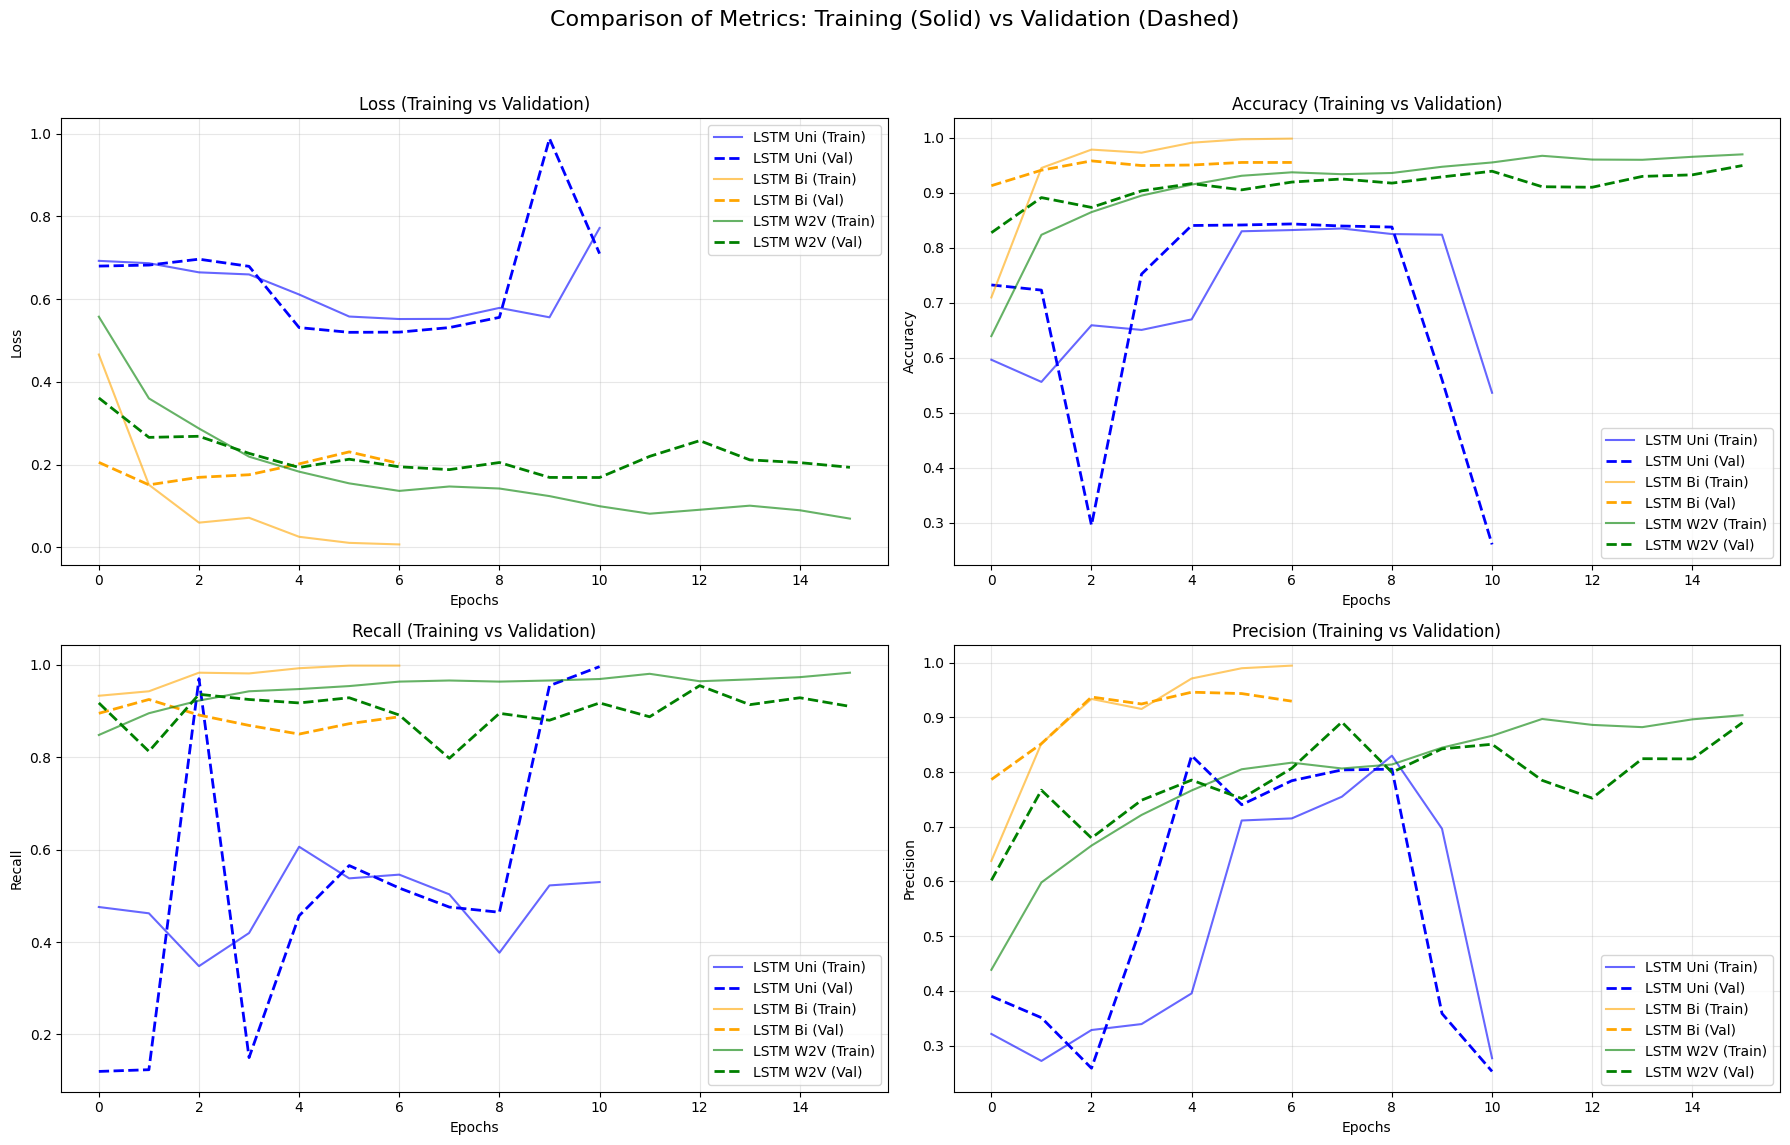

In [122]:

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

models_data = [
    (history_uni, 'LSTM Uni', 'blue'),
    (history_bi, 'LSTM Bi', 'orange'),
    (history_bi_word2vec, 'LSTM W2V', 'green')
]

# Helper function to find keys (handles 'accuracy'/'acc', 'recall_1'/'recall', etc.)
def get_metric_key(history, metric_name):
    return next((k for k in history.history.keys() if metric_name in k and 'val_' not in k), None)

# LOSS (Training & Validation)
ax = axes[0, 0]
for hist, label, color in models_data:
    # Train
    ax.plot(hist.history['loss'], label=f'{label} (Train)', color=color, linestyle='-', alpha=0.6)
    # Val
    ax.plot(hist.history['val_loss'], label=f'{label} (Val)', color=color, linestyle='--', linewidth=2)
ax.set_title('Loss (Training vs Validation)')
ax.set_ylabel('Loss')
ax.set_xlabel('Epochs')
ax.legend()
ax.grid(True, alpha=0.3)

# ACCURACY (Training & Validation)
ax = axes[0, 1]
for hist, label, color in models_data:
    key_train = get_metric_key(hist, 'acc') # 'accuracy' or 'acc'
    if key_train:
        # Train
        ax.plot(hist.history[key_train], label=f'{label} (Train)', color=color, linestyle='-', alpha=0.6)
        # Val
        ax.plot(hist.history[f'val_{key_train}'], label=f'{label} (Val)', color=color, linestyle='--', linewidth=2)
ax.set_title('Accuracy (Training vs Validation)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Epochs')
ax.legend()
ax.grid(True, alpha=0.3)

# RECALL (Training & Validation)
ax = axes[1, 0]
for hist, label, color in models_data:
    key_train = get_metric_key(hist, 'recall')
    if key_train:
        # Train
        ax.plot(hist.history[key_train], label=f'{label} (Train)', color=color, linestyle='-', alpha=0.6)
        # Val (construct val key based on found train key)
        ax.plot(hist.history[f'val_{key_train}'], label=f'{label} (Val)', color=color, linestyle='--', linewidth=2)
ax.set_title('Recall (Training vs Validation)')
ax.set_ylabel('Recall')
ax.set_xlabel('Epochs')
ax.legend()
ax.grid(True, alpha=0.3)

# --- 4. PRECISION (Training & Validation)
ax = axes[1, 1]
for hist, label, color in models_data:
    key_train = get_metric_key(hist, 'precision')
    if key_train:
        # Train
        ax.plot(hist.history[key_train], label=f'{label} (Train)', color=color, linestyle='-', alpha=0.6)
        # Val
        ax.plot(hist.history[f'val_{key_train}'], label=f'{label} (Val)', color=color, linestyle='--', linewidth=2)
ax.set_title('Precision (Training vs Validation)')
ax.set_ylabel('Precision')
ax.set_xlabel('Epochs')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Comparison of Metrics: Training (Solid) vs Validation (Dashed)', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

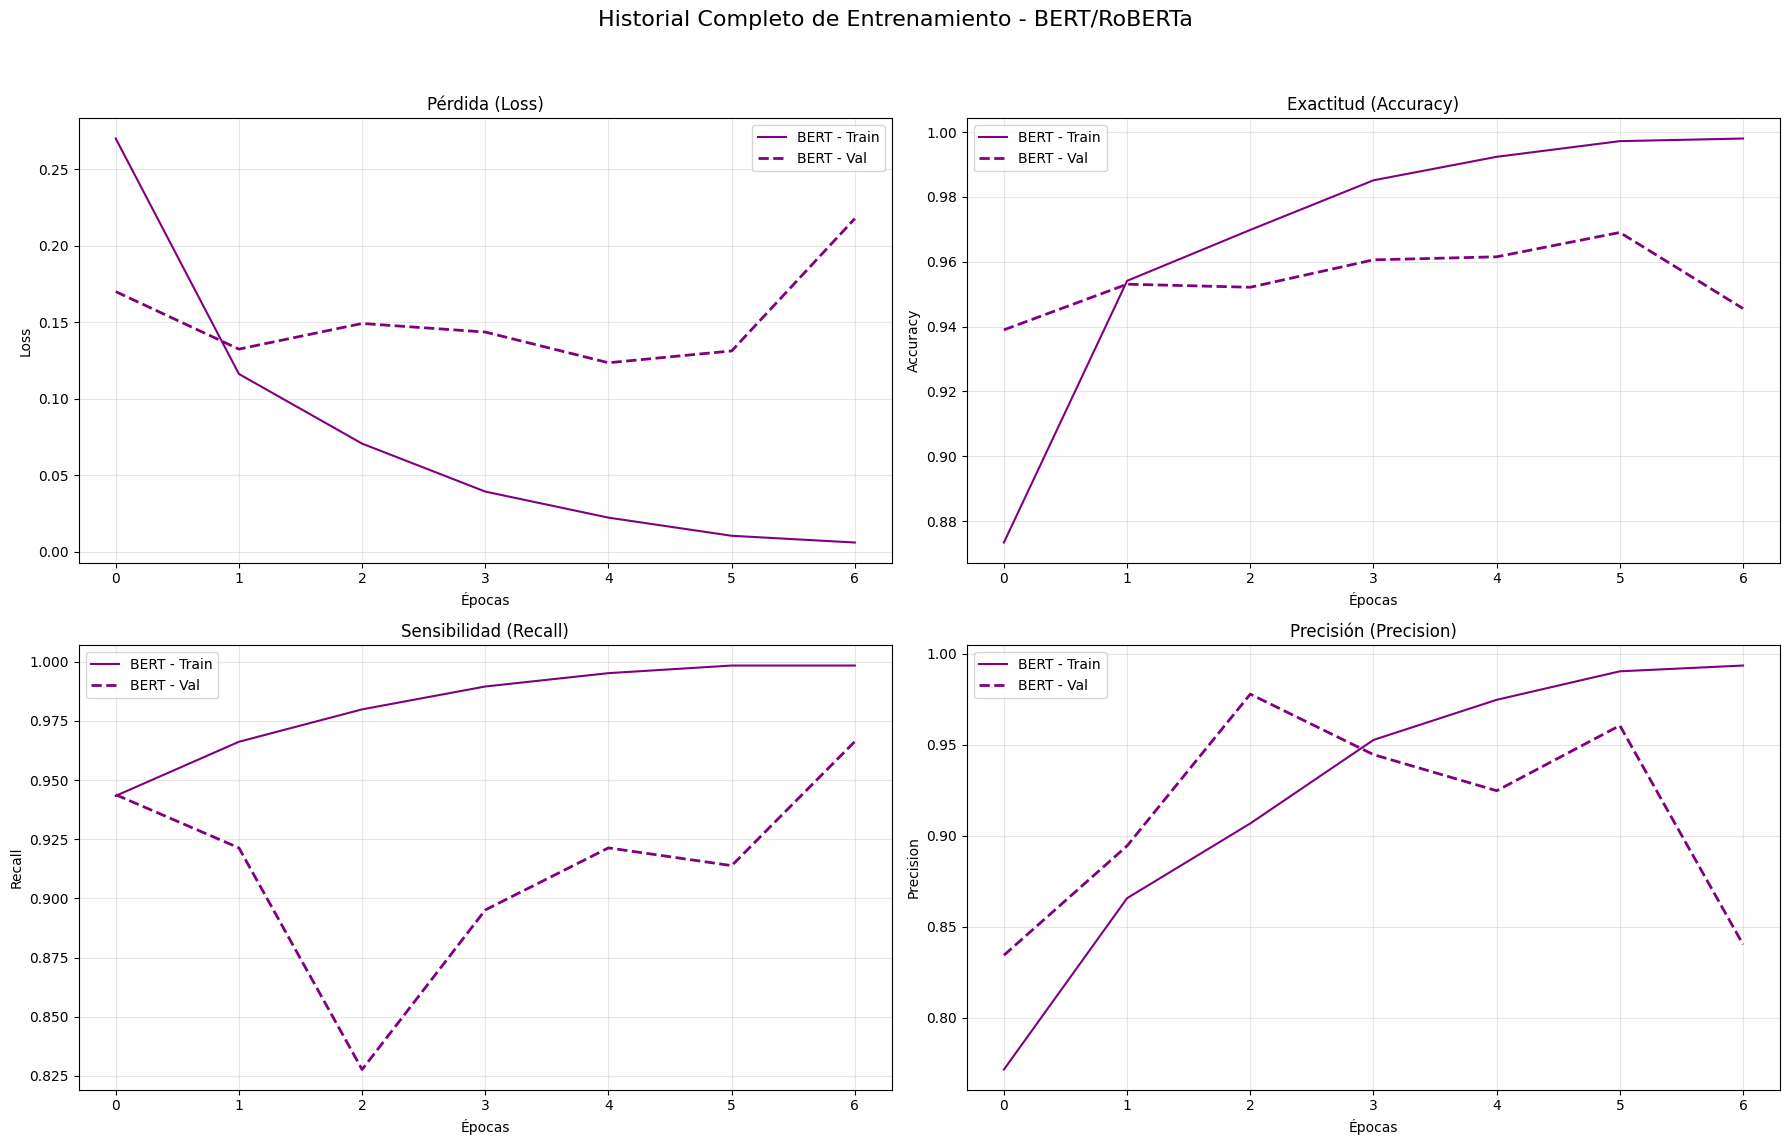

In [123]:
# Función auxiliar para encontrar claves (ej: 'accuracy' vs 'acc')
def get_metric_key(history, metric_name):
    # Busca la clave base (entrenamiento) que contenga el nombre y NO tenga 'val_'
    return next((k for k in history.history.keys() if metric_name in k and 'val_' not in k), None)

# Configuración de la figura (2 filas, 2 columnas)
fig, axes = plt.subplots(2, 2, figsize=(18, 12))
history = history_bert # Alias corto

# Estilo
COLOR = 'purple'
TRAIN_STYLE = '-'
VAL_STYLE = '--'

# LOSS
ax = axes[0, 0]
ax.plot(history.history['loss'], label='BERT - Train', color=COLOR, linestyle=TRAIN_STYLE)
ax.plot(history.history['val_loss'], label='BERT - Val', color=COLOR, linestyle=VAL_STYLE, linewidth=2)
ax.set_title('Pérdida (Loss)')
ax.set_ylabel('Loss')
ax.set_xlabel('Épocas')
ax.legend()
ax.grid(True, alpha=0.3)

# ACCURACY
ax = axes[0, 1]
key = get_metric_key(history, 'acc') # 'accuracy' o 'acc'
if key:
    ax.plot(history.history[key], label='BERT - Train', color=COLOR, linestyle=TRAIN_STYLE)
    ax.plot(history.history[f'val_{key}'], label='BERT - Val', color=COLOR, linestyle=VAL_STYLE, linewidth=2)
ax.set_title('Exactitud (Accuracy)')
ax.set_ylabel('Accuracy')
ax.set_xlabel('Épocas')
ax.legend()
ax.grid(True, alpha=0.3)

# RECALL
ax = axes[1, 0]
key = get_metric_key(history, 'recall')
if key:
    ax.plot(history.history[key], label='BERT - Train', color=COLOR, linestyle=TRAIN_STYLE)
    ax.plot(history.history[f'val_{key}'], label='BERT - Val', color=COLOR, linestyle=VAL_STYLE, linewidth=2)
ax.set_title('Sensibilidad (Recall)')
ax.set_ylabel('Recall')
ax.set_xlabel('Épocas')
ax.legend()
ax.grid(True, alpha=0.3)

# PRECISION
ax = axes[1, 1]
key = get_metric_key(history, 'precision')
if key:
    ax.plot(history.history[key], label='BERT - Train', color=COLOR, linestyle=TRAIN_STYLE)
    ax.plot(history.history[f'val_{key}'], label='BERT - Val', color=COLOR, linestyle=VAL_STYLE, linewidth=2)
ax.set_title('Precisión (Precision)')
ax.set_ylabel('Precision')
ax.set_xlabel('Épocas')
ax.legend()
ax.grid(True, alpha=0.3)

plt.suptitle('Historial Completo de Entrenamiento - BERT/RoBERTa', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()

In [ ]:
# Cargar modelos guardados
best_lstm_uni = tf.keras.models.load_model("best_model_uni.keras", compile=False)
best_lstm_bi = tf.keras.models.load_model("best_model_bi.keras", compile=False)
best_lstm_w2v = tf.keras.models.load_model("best_model_bi_word2vec.keras", compile=False)
best_bert = tf.keras.models.load_model("best_model_bert.keras", compile=False)

# Predicciones
print("Predicciones:")
THRESHOLD = 0.8 

# LSTMs (Usan X_test)
y_pred_uni = (best_lstm_uni.predict(X_test, verbose=0) > THRESHOLD).astype(int).flatten()
y_pred_bi = (best_lstm_bi.predict(X_test, verbose=0) > THRESHOLD).astype(int).flatten()
y_pred_w2v = (best_lstm_w2v.predict(X_test, verbose=0) > THRESHOLD).astype(int).flatten()

# BERT (Usan X_test_bert)
y_pred_bert = (best_bert.predict(X_test_bert, verbose=0) > THRESHOLD).astype(int).flatten()

# Calcular Matrices
cm_uni = confusion_matrix(y_test, y_pred_uni)
cm_bi = confusion_matrix(y_test, y_pred_bi)
cm_w2v = confusion_matrix(y_test, y_pred_w2v)
cm_bert = confusion_matrix(y_test_bert, y_pred_bert)

# Visualización
fig, ax = plt.subplots(1, 4, figsize=(24, 6))
labels = ["No Spam", "Spam"]

# Plot 1: LSTM Uni
ConfusionMatrixDisplay(cm_uni, display_labels=labels).plot(ax=ax[0], cmap="Blues", colorbar=False, values_format='d')
ax[0].set_title("LSTM Unidireccional", fontsize=14, pad=15)

# Plot 2: LSTM Bi
ConfusionMatrixDisplay(cm_bi, display_labels=labels).plot(ax=ax[1], cmap="Oranges", colorbar=False, values_format='d')
ax[1].set_title("LSTM Bidireccional", fontsize=14, pad=15)

# Plot 3: LSTM W2V
ConfusionMatrixDisplay(cm_w2v, display_labels=labels).plot(ax=ax[2], cmap="Greens", colorbar=False, values_format='d')
ax[2].set_title("Bi-LSTM + Word2Vec", fontsize=14, pad=15)

# Plot 4: BERT
ConfusionMatrixDisplay(cm_bert, display_labels=labels).plot(ax=ax[3], cmap="Purples", colorbar=False, values_format='d')
ax[3].set_title("Transformer (BERT)", fontsize=14, pad=15)

# Ajuste de fuentes
for ax_i in ax:
    for text in ax_i.texts:
        text.set_fontsize(18)
    ax_i.set_xlabel("Predicción", fontsize=12)
    ax_i.set_ylabel("Realidad", fontsize=12)

plt.suptitle("Matrices de Confusión: Comparativa de Modelos", fontsize=20, y=1.05)
plt.tight_layout()
plt.show()

### Conclusiones

En la comparación guardada, BERT obtuvo 95,31 % de exactitud y 0,8736 de MCC con umbral 0,8. La BiLSTM con GloVe obtuvo 93,62 % y 0,8331. Los nombres «W2V» de algunas celdas se refieren al modelo que carga `glove-twitter-100`.

El tokenizer de las LSTM se ajustó antes de dividir el conjunto. Para una comparación nueva, conviene ajustarlo con los textos de entrenamiento y aplicar la misma partición a todos los modelos.

## Generación del CSV final de Predicciones

Una vez **definido y entrenado tu modelo** (no incluido en esta plantilla) y generadas tus predicciones sobre el conjunto de prueba `test`, crea el archivo `submission.csv` con el siguiente formato:

```text
row_id,spam_label
7097,0
7098,0
7099,1
...
````

Donde:

* `row_id` es el identificador del texto en el conjunto de test.
* `spam_label` es `0` para **NO SPAM** y `1` para **SPAM**.

In [ ]:
# Cargar el archivo de ejemplo de envío
submission = pd.read_csv(f"{DATASET_DIR}/sample_submission.csv")

# PREDICCIÓN

# 1. Predecimos sobre la columna de texto del dataframe 'test' original
raw_probs = classifier.predict(test["text"], verbose=1, batch_size=32).flatten()

# 2. Convertimos probabilidad a clase 0 o 1 (Enteros)
y_pred = (raw_probs > 0.8).astype(int)


# Reemplazar la columna con tus predicciones
submission["spam_label"] = y_pred

# Guardar el archivo en el formato requerido
output_path = "submission.csv"
submission.to_csv(output_path, index=False)

print(f"Archivo guardado correctamente como: {output_path}")
submission.head()